Original distribution:
 Class
0    284315
1       492
Name: count, dtype: int64
Balanced distribution: [227451  56862]


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(



===== FINAL RESULTS =====
Best Threshold: 0.97295135482258
Accuracy: 0.9995786664794073
ROC-AUC: 0.9767427546426561
PR-AUC: 0.8653108849627968
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56864
           1       0.94      0.81      0.87        98

    accuracy                           1.00     56962
   macro avg       0.97      0.90      0.93     56962
weighted avg       1.00      1.00      1.00     56962



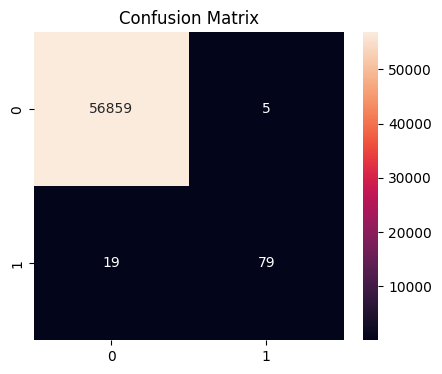

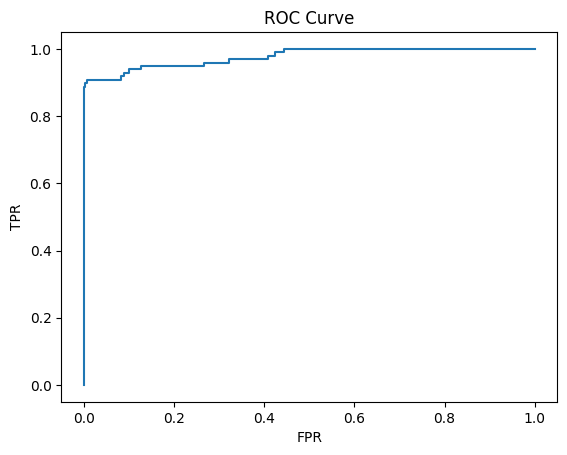

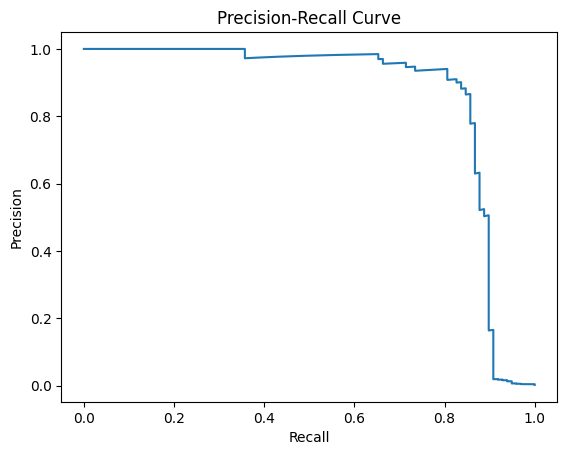

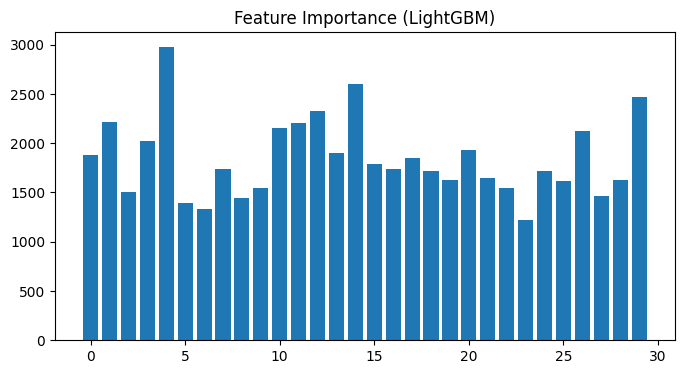

In [2]:

!pip install -q lightgbm xgboost imbalanced-learn

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import RobustScaler
from sklearn.feature_selection import VarianceThreshold
from sklearn.metrics import (classification_report, roc_auc_score,
                             average_precision_score, accuracy_score,
                             precision_recall_curve, roc_curve,
                             confusion_matrix)

from imblearn.over_sampling import SMOTE

from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import VotingClassifier


df = pd.read_csv("creditcard.csv")

print("Original distribution:\n", df['Class'].value_counts())


df['Amount_log'] = np.log1p(df['Amount'])


for col in df.columns:
    if col not in ['Class']:
        df[col] = np.clip(df[col], df[col].quantile(0.01), df[col].quantile(0.99))

# Drop unused raw features
df = df.drop(['Amount'], axis=1)


X = df.drop('Class', axis=1)
y = df['Class']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)


selector = VarianceThreshold(threshold=0.0001)
X_train = selector.fit_transform(X_train)
X_test = selector.transform(X_test)


scaler = RobustScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)


smote = SMOTE(sampling_strategy=0.25, random_state=42)
X_train_res, y_train_res = smote.fit_resample(X_train, y_train)

print("Balanced distribution:", np.bincount(y_train_res))


lgbm = LGBMClassifier(
    n_estimators=700,
    learning_rate=0.03,
    max_depth=8,
    num_leaves=80,
    subsample=0.85,
    colsample_bytree=0.85,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1,
    verbose=-1
)

xgb = XGBClassifier(
    n_estimators=600,
    max_depth=6,
    learning_rate=0.03,
    subsample=0.85,
    colsample_bytree=0.85,
    scale_pos_weight=10,
    eval_metric='logloss',
    random_state=42,
    n_jobs=-1
)

logreg = LogisticRegression(max_iter=2000)


model = VotingClassifier(
    estimators=[
        ('lgbm', lgbm),
        ('xgb', xgb),
        ('lr', logreg)
    ],
    voting='soft',
    n_jobs=-1
)


model.fit(X_train_res, y_train_res)


probs = model.predict_proba(X_test)[:, 1]


precision, recall, thresholds = precision_recall_curve(y_test, probs)
f1 = 2 * (precision * recall) / (precision + recall + 1e-8)

best_idx = np.argmax(f1)
best_threshold = thresholds[best_idx]

preds = (probs >= best_threshold).astype(int)


acc = accuracy_score(y_test, preds)
roc = roc_auc_score(y_test, probs)
pr = average_precision_score(y_test, probs)

print("\n===== FINAL RESULTS =====")
print("Best Threshold:", best_threshold)
print("Accuracy:", acc)
print("ROC-AUC:", roc)
print("PR-AUC:", pr)
print(classification_report(y_test, preds))


cm = confusion_matrix(y_test, preds)

plt.figure(figsize=(5,4))
sns.heatmap(cm, annot=True, fmt='d')
plt.title("Confusion Matrix")
plt.show()


fpr, tpr, _ = roc_curve(y_test, probs)

plt.figure()
plt.plot(fpr, tpr)
plt.title("ROC Curve")
plt.xlabel("FPR")
plt.ylabel("TPR")
plt.show()


plt.figure()
plt.plot(recall, precision)
plt.title("Precision-Recall Curve")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.show()


lgbm.fit(X_train_res, y_train_res)
importances = lgbm.feature_importances_

plt.figure(figsize=(8,4))
plt.bar(range(len(importances)), importances)
plt.title("Feature Importance (LightGBM)")
plt.show()